# LEP-17 : Analyser les facteurs sanitaires associés à l’espérance de vie

**Projet** : WHO Life Expectancy  
**Sprint** : 4  
**Source des données** : `data/processed/life_expectancy_fiabilise.csv`

## Contexte et objectif

Un responsable de programme de santé souhaite savoir quels indicateurs sanitaires
présentent les associations les plus marquées avec l’espérance de vie. Cette analyse
aidera à déterminer quelles relations méritent d’être approfondies pour éclairer
les priorités d’intervention sanitaire.

## Question analytique

Quels indicateurs sanitaires sont les plus fortement associés à l’espérance de vie,
et dans quel sens ces associations vont-elles ?

## Démarche

1. Sélectionner les variables sanitaires pertinentes.
2. Évaluer la qualité des variables sélectionnées.
3. Préparer les variables pour l’analyse.
4. Mesurer les associations avec l’espérance de vie.
5. Visualiser et interpréter les relations observées.

Les résultats seront interprétés comme des associations statistiques.


## 1. Chargement et vérification des données

In [15]:
# Bibliothèques
from zipfile import ZipFile
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
# Charger le jeu de données fiabilisé
df_copy = pd.read_csv("../data/processed/life_expectancy_fiabilise.csv")

In [ ]:
# Vérifier les colonnes présentes
df_copy.columns.to_list()

['country',
 'year',
 'status',
 'life_expectancy',
 'adult_mortality',
 'infant_deaths',
 'alcohol',
 'hepatitis_b',
 'measles',
 'under_five_deaths',
 'polio',
 'total_expenditure',
 'diphtheria',
 'hiv_aids',
 'gdp',
 'population',
 'thinness_10_19_years',
 'thinness_5_9_years',
 'income_composition_of_resources',
 'schooling',
 'iso3',
 'health_expenditure_pc_usd',
 'overweight_adults_pct_oms']

In [5]:
# Identifier le pays et l'année de chaque observation.
colonnes_identification = ["country", "iso3", "year"]

# Définir la variable à expliquer.
variable_cible = "life_expectancy"

# Sélectionner les indicateurs sanitaires à examiner.
variables_sanitaires = [
    "adult_mortality",
    "infant_deaths",
    "under_five_deaths",
    "hiv_aids",
    "hepatitis_b",
    "measles",
    "polio",
    "diphtheria",
    "overweight_adults_pct_oms",
]

# Créer un DataFrame de travail en conservant toutes les observations.
colonnes_lep17 = colonnes_identification + [variable_cible] + variables_sanitaires
df = df_copy.loc[:, colonnes_lep17].copy()

# Afficher les dimensions et un aperçu du nouveau DataFrame.
print(f"{df.shape[0]:,} lignes et {df.shape[1]} colonnes")
display(df.head())

2,938 lignes et 13 colonnes


,country,iso3,year,life_expectancy,adult_mortality,infant_deaths,under_five_deaths,hiv_aids,hepatitis_b,measles,polio,diphtheria,overweight_adults_pct_oms
0,Afghanistan,AFG,2015,62.270,263.0,62,83,0.1,64.0,1154,6.0,64.0,37.67
1,Afghanistan,AFG,2014,62.260,271.0,64,86,0.1,62.0,492,58.0,62.0,36.17
2,Afghanistan,AFG,2013,62.188,268.0,66,89,0.1,64.0,430,62.0,64.0,34.71
3,Afghanistan,AFG,2012,61.735,272.0,69,93,0.1,67.0,2787,67.0,67.0,33.28
4,Afghanistan,AFG,2011,61.250,275.0,71,97,0.1,68.0,3013,68.0,68.0,31.89


## 2. Évaluer la qualité des variables sanitaires.

### 2.1. Bilan de qualité

In [6]:
# Résumer le type et les valeurs manquantes pour les 13 colonnes de LEP-17.
qualite_variables = pd.DataFrame({
    "type": df[colonnes_lep17].dtypes.astype(str),
    "valeurs_manquantes": df[colonnes_lep17].isna().sum(),
    "pct_manquant": df[colonnes_lep17].isna().mean().mul(100).round(2),
})

# Afficher en premier les colonnes les plus incomplètes.
display(qualite_variables.sort_values("pct_manquant", ascending=False))

,type,valeurs_manquantes,pct_manquant
hepatitis_b,float64,559,19.03
polio,float64,19,0.65
diphtheria,float64,19,0.65
adult_mortality,float64,10,0.34
life_expectancy,float64,2,0.07
overweight_adults_pct_oms,float64,2,0.07
iso3,object,0,0.00
country,object,0,0.00
year,int64,0,0.00
hiv_aids,float64,0,0.00


Sur les 2 938 observations pays–année, hepatitis_b est la seule colonne qui dépasse 1 % de valeurs manquantes : 559 observations, soit 19,03 %. L’espérance de vie manque dans seulement 2 observations, et les trois colonnes d’identification (country, iso3, year) sont complètes.

### 2.2. Vérification de la couverture de l’hépatite B par année

In [7]:
# Compter les observations et les valeurs manquantes par année.
couverture_hepatite_b = df.groupby("year")["hepatitis_b"].agg(
    observations="size",
    valeurs_disponibles="count",
)

# Calculer la proportion de valeurs manquantes pour chaque année.
couverture_hepatite_b["valeurs_manquantes"] = (
    couverture_hepatite_b["observations"]
    - couverture_hepatite_b["valeurs_disponibles"]
)

couverture_hepatite_b["pct_manquant"] = (
    couverture_hepatite_b["valeurs_manquantes"]
    .div(couverture_hepatite_b["observations"])
    .mul(100)
    .round(2)
)

display(couverture_hepatite_b)

,observations,valeurs_disponibles,valeurs_manquantes,pct_manquant
year,,,,
2000,183,84,99,54.10
2001,183,94,89,48.63
2002,183,112,71,38.80
2003,183,130,53,28.96
2004,183,138,45,24.59
2005,183,146,37,20.22
2006,183,150,33,18.03
2007,183,159,24,13.11
2008,183,163,20,10.93


Les valeurs manquantes de hepatitis_b se concentrent au début de la période. Elles passent de 54,10 % en 2000 à 5,70 % en 2013, puis à 4,92 % en 2015.

### 2.3. Vérifier la couverture des autres indicateurs en 2013

In [8]:
# Garder les observations de 2013 dont l'espérance de vie est renseignée.
df_2013 = df.loc[df["year"].eq(2013)]
df_2013_cible_disponible = df_2013.dropna(subset=[variable_cible])

# Compter les observations utilisables pour chaque association.
couverture_2013 = (
    df_2013_cible_disponible[variables_sanitaires]
    .count()
    .rename("observations_utilisables")
    .to_frame()
    .sort_values("observations_utilisables")
)

display(couverture_2013)

,observations_utilisables
hepatitis_b,180
adult_mortality,183
overweight_adults_pct_oms,189
under_five_deaths,191
hiv_aids,191
measles,191
polio,191
infant_deaths,191
diphtheria,191


### 2.4 Vérifions que chaque code pays apparaît une seule fois en 2013.
 C’est ce qui nous permettra de dire que chaque ligne représente un pays dans l’analyse.

In [9]:
# Afficher les codes pays qui apparaissent plusieurs fois en 2013.
doublons_2013 = df_2013.loc[
    df_2013.duplicated(subset="iso3", keep=False),
    ["country", "iso3", "year"],
]

display(doublons_2013)

,country,iso3,year


### 2.5 Compter les paires (année-indicateur) disponibles par année

In [10]:
# Garder les observations où l'espérance de vie est renseignée.
df_cible_disponible = df.dropna(subset=[variable_cible])

# Compter les valeurs renseignées pour chaque indicateur et chaque année.
paires_disponibles_par_annee = (
    df_cible_disponible.groupby("year")[variables_sanitaires].count()
)

display(paires_disponibles_par_annee)

,adult_mortality,infant_deaths,under_five_deaths,hiv_aids,hepatitis_b,measles,polio,diphtheria,overweight_adults_pct_oms
year,,,,,,,,,
2000,183,183,183,183,84,183,180,180,183
2001,183,183,183,183,94,183,180,180,183
2002,183,183,183,183,112,183,181,181,183
2003,183,183,183,183,130,183,181,181,183
2004,183,183,183,183,138,183,181,181,183
2005,183,183,183,183,146,183,181,181,183
2006,183,183,183,183,150,183,182,182,183
2007,183,183,183,183,159,183,182,182,183
2008,183,183,183,183,163,183,182,182,183


Le tableau confirme qu’on peut étudier les associations année par année de 2000 à 2015. Pour huit indicateurs sur neuf, on dispose d’au moins 180 paires chaque année. L’hépatite B est l’exception : elle passe de 84 paires en 2000 à 174 en 2015, avec un maximum de 180 en 2013.

Avant de calculer les corrélations, vérifions si ce sont les mêmes pays qui reviennent chaque année. Un effectif de 183 deux années de suite peut correspondre à des pays différents. Ce contrôle nous donnera un groupe de pays commun pour une éventuelle analyse de sensibilité.

In [11]:
# Compter, pour chaque pays, les années où l'espérance de vie est renseignée.
nb_annees_par_pays = df_cible_disponible.groupby("iso3")["year"].nunique()
nb_annees = df_cible_disponible["year"].nunique()

# Repérer les pays présents durant toute la période.
pays_communs = nb_annees_par_pays[nb_annees_par_pays.eq(nb_annees)].index

print(f"{len(pays_communs)} pays avec une espérance de vie renseignée sur {nb_annees} ans")

183 pays avec une espérance de vie renseignée sur 16 ans


Les 183 mêmes pays ont une espérance de vie renseignée chaque année de 2000 à 2015. En 2013, on compte 191 pays avec une espérance de vie renseignée, dont 8 en dehors de ce groupe commun.

Pour LEP-17, je garderais toutes les paires disponibles dans l’analyse principale. Le groupe des 183 pays nous servira à vérifier si les conclusions changent quand on restreint la comparaison aux pays suivis sur toute la période.

In [12]:
# Vérifier la couverture dans les 183 pays communs aux variables sanitaires

# Garder les pays dont l'espérance de vie est renseignée sur les 16 ans.
df_pays_communs = df_cible_disponible.loc[
    df_cible_disponible["iso3"].isin(pays_communs)
].copy()

# Compter les paires disponibles par année dans ce groupe.
paires_pays_communs = (
    df_pays_communs.groupby("year")[variables_sanitaires].count()
)

display(paires_pays_communs)

,adult_mortality,infant_deaths,under_five_deaths,hiv_aids,hepatitis_b,measles,polio,diphtheria,overweight_adults_pct_oms
year,,,,,,,,,
2000,183,183,183,183,84,183,180,180,183
2001,183,183,183,183,94,183,180,180,183
2002,183,183,183,183,112,183,181,181,183
2003,183,183,183,183,130,183,181,181,183
2004,183,183,183,183,138,183,181,181,183
2005,183,183,183,183,146,183,181,181,183
2006,183,183,183,183,150,183,182,182,183
2007,183,183,183,183,159,183,182,182,183
2008,183,183,183,183,163,183,182,182,183


Le tableau confirme que six indicateurs sont renseignés pour les 183 pays pendant les 16 années. La polio et la diphtérie atteignent cette couverture à partir de 2011. Pour l’hépatite B, elle passe de 84 pays en 2000 à 174 en 2015. En 2013, on a 172 paires dans le groupe commun, contre 180 dans l’ensemble des pays disponibles cette année-là.

On garde toutes les paires disponibles pour l’analyse principale. Le groupe des 183 pays servira à vérifier si la composition de l’échantillon influence les résultats.

In [13]:
# Vérifier les doublons sur toute la période

# Afficher les lignes dont le couple pays–année se répète.
doublons_pays_annee = df.loc[
    df.duplicated(subset=["iso3", "year"], keep=False),
    ["country", "iso3", "year"],
].sort_values(["iso3", "year"])

display(doublons_pays_annee)

,country,iso3,year


Le tableau vide confirme que chaque couple iso3–`year` apparaît une seule fois. Dans les tableaux précédents, les effectifs correspondent donc bien à des nombres de pays par année.

Le notebook de fiabilisation signale que la définition et l’unité de infant_deaths et under_five_deaths restent à confirmer. Je n’y ai pas trouvé d’unité documentée pour measles. La distinction compte : un nombre de décès ou de cas peut être plus élevé dans un pays simplement parce qu’il est plus peuplé.

In [14]:
# Vérifier les unités des variables avant de calculer les corrélations
# Examiner les distributions des trois indicateurs dont l'unité reste à confirmer.
colonnes_unites = ["infant_deaths", "under_five_deaths", "measles"]
resume_unites = df[colonnes_unites].describe(percentiles=[0.5, 0.95, 0.99]).T
resume_unites["nb_zeros"] = df[colonnes_unites].eq(0).sum()

display(resume_unites.round(2))

,count,mean,std,min,50%,95%,99%,max,nb_zeros
infant_deaths,2938.0,30.30,117.93,0.0,3.0,94.15,495.04,1800.0,848
under_five_deaths,2938.0,42.04,160.45,0.0,4.0,138.00,767.82,2500.0,785
measles,2938.0,2419.59,11467.27,0.0,17.0,9985.55,54163.36,212183.0,983


### Constat sur les unités des indicateurs sanitaires

Les colonnes `infant_deaths`, `under_five_deaths` et `measles` sont renseignées pour les 2 938 observations. Leur complétude ne suffit toutefois pas à établir que leurs valeurs sont comparables entre pays.

- **Décès infantiles et décès avant cinq ans.** Les maxima observés (1 800 et 2 500) sont incompatibles avec une interprétation comme taux de mortalité pour 1 000 naissances vivantes. L’unité et l’échelle des valeurs d’origine restent à confirmer.
- **Rougeole.** Pour la Chine en 2008, la valeur du jeu de données (131 441) correspond au nombre de cas déclarés dans la source officielle. Cette concordance appuie l’interprétation de la colonne comme un effectif de cas déclarés. Le sens des 983 zéros observés dans le jeu de données reste à confirmer.

Ces limites influencent l’interprétation des associations avec l’espérance de vie. Un effectif de décès ou de cas dépend notamment de la taille de la population concernée. Pour comparer les pays sur une base commune, nous retenons des indicateurs officiels dont la définition et l’unité sont documentées : les taux de mortalité infantile et avant cinq ans pour 1 000 naissances vivantes, ainsi que l’incidence déclarée de la rougeole rapportée à la population.

## 3. Préparer une version fiabilisée des indicateurs sanitaires

Nous réutilisons l’archive WDI de la Banque mondiale pour extraire deux indicateurs officiels : le taux de mortalité infantile (`SP.DYN.IMRT.IN`) et le taux de mortalité avant cinq ans (`SH.DYN.MORT`). Ces deux taux sont exprimés pour 1 000 naissances vivantes et remplaceront les colonnes `infant_deaths` et `under_five_deaths`, dont l’unité reste à confirmer.

Nous ajouterons ensuite l’incidence déclarée de la rougeole issue de l’OMS et de l’UNICEF pour remplacer la colonne `measles`. Les trois séries seront jointes au jeu fiabilisé complet à partir du code pays `iso3` et de l’année `year`.

Avant l’exportation, nous vérifierons que les 2 938 observations sont conservées, que chaque couple pays–année reste unique et que la couverture des nouveaux indicateurs est documentée. La nouvelle version sera enregistrée dans `life_expectancy_fiabilise_sanitaire.csv`. Le CSV fiabilisé actuel sera conservé pour permettre la reproduction des analyses précédentes.

### 3.1 Extraire les deux taux de mortalité de l’archive WDI

On lit WDICSV.csv par blocs pour extraire les deux indicateurs sur la période 2000–2015.

In [17]:
from pathlib import Path

# Indiquer où se trouve l'archive WDI depuis le dossier notebooks/.
fichier_wdi = Path("../data/external/WDI_CSV_2026_10_08.zip")

# Vérifier que Python trouve bien l'archive.
print(fichier_wdi.is_file())

True


In [18]:
display(list(Path("../data/external").glob("WDI_CSV_2026_10_08*")))

[WindowsPath('../data/external/WDI_CSV_2026_10_08.zip')]

In [19]:
# Définir les codes des deux indicateurs officiels.
indicateurs_mortalite_wb = {
    "SP.DYN.IMRT.IN": "infant_mortality_per_1000_live_births",
    "SH.DYN.MORT": "under_five_mortality_per_1000_live_births",
}

# Sélectionner les colonnes nécessaires pour la période de l'étude.
annees_etude = [str(annee) for annee in range(2000, 2016)]
colonnes_wdi = ["Country Code", "Indicator Code"] + annees_etude

# Lire l'archive existante et conserver les deux séries recherchées.
extraits_mortalite = []

with ZipFile(fichier_wdi) as archive:
    with archive.open("WDICSV.csv") as fichier:
        for bloc in pd.read_csv(fichier, usecols=colonnes_wdi, chunksize=10_000):
            selection = bloc.loc[
                bloc["Indicator Code"].isin(indicateurs_mortalite_wb)
            ]
            if not selection.empty:
                extraits_mortalite.append(selection)

wdi_mortalite = pd.concat(extraits_mortalite, ignore_index=True)

# Vérifier que les deux codes sont présents.
display(wdi_mortalite["Indicator Code"].value_counts())

Indicator Code
SP.DYN.IMRT.IN    266
SH.DYN.MORT       266
Name: count, dtype: int64

In [20]:
# Préparer le tableau pour la jointure

# Transformer les colonnes d'années en lignes.
wdi_mortalite_long = (
    wdi_mortalite
    .rename(columns={"Country Code": "iso3"})
    .melt(
        id_vars=["iso3", "Indicator Code"],
        value_vars=annees_etude,
        var_name="year",
        value_name="taux",
    )
    .astype({"year": int})
)

# Placer les deux taux dans des colonnes distinctes.
wdi_mortalite_pays_annee = (
    wdi_mortalite_long
    .pivot(index=["iso3", "year"], columns="Indicator Code", values="taux")
    .rename(columns=indicateurs_mortalite_wb)
    .rename_axis(columns=None)
    .reset_index()
)

display(wdi_mortalite_pays_annee.head())

,iso3,year,under_five_mortality_per_1000_live_births,infant_mortality_per_1000_live_births
0,ABW,2000,NaN,NaN
1,ABW,2001,NaN,NaN
2,ABW,2002,NaN,NaN
3,ABW,2003,NaN,NaN
4,ABW,2004,NaN,NaN


### Acquisition des données officielles sur la rougeole

Nous avons téléchargé le fichier `incidence-rate-data-who` depuis le portail de données de vaccination de l’OMS. Cet export contient les taux d’incidence déclarée de plusieurs maladies, recueillis dans le cadre du rapport annuel conjoint de l’OMS et de l’UNICEF.

Pour la rougeole, l’indicateur mesure le nombre de cas déclarés par million d’habitants. Cette mesure tient compte de la taille de la population et permet de comparer les pays sur une même échelle. Les différences de surveillance et de déclaration entre pays restent une limite à prendre en compte.

Le fichier source est conservé dans `data/external/`. Nous en extrairons les données sur la rougeole pour la période 2000–2015, puis les préparerons pour la jointure par pays et par année. Les valeurs absentes resteront manquantes.

In [21]:
from pathlib import Path

import pandas as pd

# Trouver le fichier téléchargé par son nom.
dossier_sources = Path("../data/external")
fichiers_incidence = [
    fichier
    for fichier in dossier_sources.glob("incidence-rate-data-who*")
    if fichier.is_file() and fichier.suffix.lower() in {".csv", ".xlsx"}
]

if len(fichiers_incidence) != 1:
    raise ValueError(f"Un seul fichier est attendu. Fichiers trouvés : {fichiers_incidence}")

fichier_incidence = fichiers_incidence[0]
print(f"Fichier trouvé : {fichier_incidence.name}")

# Ouvrir le fichier selon son extension.
if fichier_incidence.suffix.lower() == ".csv":
    incidence_oms_brute = pd.read_csv(fichier_incidence, sep=None, engine="python")
else:
    with pd.ExcelFile(fichier_incidence) as classeur:
        print("Feuilles disponibles :", classeur.sheet_names)
        incidence_oms_brute = classeur.parse(sheet_name=0)

# Afficher les colonnes et un aperçu des données.
print(incidence_oms_brute.columns.to_list())
display(incidence_oms_brute.head())

Fichier trouvé : incidence-rate-data-who.xlsx
Feuilles disponibles : ['Data', 'Reference']
['GROUP', 'CODE', 'NAME', 'YEAR', 'DISEASE', 'DISEASE_DESCRIPTION', 'DENOMINATOR', 'INCIDENCE_RATE']


,GROUP,CODE,NAME,YEAR,DISEASE,DISEASE_DESCRIPTION,DENOMINATOR,INCIDENCE_RATE
0,COUNTRIES,ABW,Aruba,2025.0,CRS,Congenital rubella syndrome,"per 10,000 live births",NaN
1,COUNTRIES,ABW,Aruba,2025.0,DIPHTHERIA,Diphtheria,"per 1,000,000 total population",NaN
2,COUNTRIES,ABW,Aruba,2025.0,INVASIVE_MENING,Invasive meningococcal disease,"per 1,000,000 total population",NaN
3,COUNTRIES,ABW,Aruba,2025.0,MEASLES,Measles,"per 1,000,000 total population",NaN
4,COUNTRIES,ABW,Aruba,2025.0,MUMPS,Mumps,"per 1,000,000 total population",NaN


L’aperçu confirme que la feuille Data contient la rougeole sous le code MEASLES, avec l’unité cas déclarés par million d’habitants. Filtrons maintenant les lignes de pays pour 2000 à 2015, puis vérifions que cette unité est utilisée sur toute la période.

In [22]:
# Garder les lignes de pays pour la rougeole sur la période de l'étude.
rougeole_oms = incidence_oms_brute.loc[
    incidence_oms_brute["GROUP"].eq("COUNTRIES")
    & incidence_oms_brute["DISEASE"].eq("MEASLES")
    & incidence_oms_brute["YEAR"].between(2000, 2015),
    ["CODE", "YEAR", "DENOMINATOR", "INCIDENCE_RATE"],
].copy()

# Vérifier les unités présentes dans les lignes retenues.
display(rougeole_oms["DENOMINATOR"].value_counts(dropna=False))

# Préparer les colonnes pour la jointure avec le jeu fiabilisé.
rougeole_pays_annee = (
    rougeole_oms
    .rename(columns={
        "CODE": "iso3",
        "YEAR": "year",
        "INCIDENCE_RATE": "measles_reported_incidence_per_million",
    })
    .drop(columns="DENOMINATOR")
    .astype({"year": int})
)

# Vérifier que chaque couple pays–année est unique.
nb_doublons = rougeole_pays_annee.duplicated(subset=["iso3", "year"]).sum()
print(f"Lignes en double sur iso3 et year : {nb_doublons}")

display(rougeole_pays_annee.head())

DENOMINATOR
per 1,000,000 total population    3156
Name: count, dtype: int64

Lignes en double sur iso3 et year : 0


,iso3,year,measles_reported_incidence_per_million
218,AFG,2015,34.1
229,AFG,2014,15.0
240,AFG,2013,13.6
251,AFG,2012,91.2
262,AFG,2011,102.7


Les 3 156 lignes de la source rougeole utilisent la même unité, cas déclarés par million d’habitants, et aucun couple iso3–`year` n’est en double. Le tableau est prêt pour la jointure.

In [23]:
# Joindre les trois indicateurs et vérifier leur couverture

# Recharger le jeu fiabilisé complet.
df_fiabilise_base = pd.read_csv("../data/processed/life_expectancy_fiabilise.csv")

# Joindre les deux taux de mortalité et l'incidence déclarée de la rougeole.
cles = ["iso3", "year"]

df_sanitaire_comparaison = (
    df_fiabilise_base
    .merge(wdi_mortalite_pays_annee, on=cles, how="left", validate="one_to_one")
    .merge(rougeole_pays_annee, on=cles, how="left", validate="one_to_one")
)

# Vérifier les dimensions après les jointures.
print("Avant les jointures :", df_fiabilise_base.shape)
print("Après les jointures :", df_sanitaire_comparaison.shape)

# Mesurer la couverture des trois nouvelles colonnes dans le jeu du projet.
nouvelles_colonnes = [
    *indicateurs_mortalite_wb.values(),
    "measles_reported_incidence_per_million",
]
indicateurs_officiels = df_sanitaire_comparaison[nouvelles_colonnes]

couverture_indicateurs = pd.DataFrame({
    "valeurs_disponibles": indicateurs_officiels.count(),
    "valeurs_manquantes": indicateurs_officiels.isna().sum(),
    "pct_manquant": indicateurs_officiels.isna().mean().mul(100).round(2),
})

display(couverture_indicateurs)

Avant les jointures : (2938, 23)
Après les jointures : (2938, 26)


,valeurs_disponibles,valeurs_manquantes,pct_manquant
infant_mortality_per_1000_live_births,2936,2,0.07
under_five_mortality_per_1000_live_births,2936,2,0.07
measles_reported_incidence_per_million,2776,162,5.51


Les jointures ont conservé les 2 938 observations. Les deux taux de mortalité ont chacun 2 valeurs manquantes (0,07 %). Pour la rougeole, 162 valeurs sont manquantes (5,51 %). On garde ces valeurs manquantes telles quelles et, dans LEP-17, on vérifiera leur répartition par année avant de calculer les corrélations.

In [24]:
# Retirer les anciennes colonnes et exporter le nouveau CSV

# Retirer les trois colonnes remplacées par les indicateurs officiels.
anciennes_colonnes = ["infant_deaths", "under_five_deaths", "measles"]
df_fiabilise_sanitaire = df_sanitaire_comparaison.drop(columns=anciennes_colonnes)

# Vérifier les dimensions avant l'exportation.
assert df_fiabilise_sanitaire.shape == df_fiabilise_base.shape

# Exporter la nouvelle version du jeu fiabilisé.
fichier_sanitaire = Path("../data/processed/life_expectancy_fiabilise_sanitaire.csv")
df_fiabilise_sanitaire.to_csv(fichier_sanitaire, index=False, encoding="utf-8-sig")

print(f"Fichier exporté : {fichier_sanitaire}")
print(f"Dimensions : {df_fiabilise_sanitaire.shape}")

Fichier exporté : ..\data\processed\life_expectancy_fiabilise_sanitaire.csv
Dimensions : (2938, 23)


In [25]:
# Associer chaque ancienne colonne à son indicateur officiel.
remplacements_sanitaires = {
    "infant_deaths": "infant_mortality_per_1000_live_births",
    "under_five_deaths": "under_five_mortality_per_1000_live_births",
    "measles": "measles_reported_incidence_per_million",
}

# Mettre à jour la liste des indicateurs sans changer leur ordre.
variables_sanitaires = [
    remplacements_sanitaires.get(colonne, colonne)
    for colonne in variables_sanitaires
]

# Reconstruire le tableau d'analyse avec les indicateurs officiels.
colonnes_lep17 = colonnes_identification + [variable_cible] + variables_sanitaires
df = df_fiabilise_sanitaire.loc[:, colonnes_lep17].copy()

print(f"{df.shape[0]} lignes et {df.shape[1]} colonnes")
display(df.head())

2938 lignes et 13 colonnes


,country,iso3,year,life_expectancy,adult_mortality,infant_mortality_per_1000_live_births,under_five_mortality_per_1000_live_births,hiv_aids,hepatitis_b,measles_reported_incidence_per_million,polio,diphtheria,overweight_adults_pct_oms
0,Afghanistan,AFG,2015,62.270,263.0,64.0,71.9,0.1,64.0,34.1,6.0,64.0,37.67
1,Afghanistan,AFG,2014,62.260,271.0,66.2,74.6,0.1,62.0,15.0,58.0,62.0,36.17
2,Afghanistan,AFG,2013,62.188,268.0,68.6,77.6,0.1,64.0,13.6,62.0,64.0,34.71
3,Afghanistan,AFG,2012,61.735,272.0,71.2,80.8,0.1,67.0,91.2,67.0,67.0,33.28
4,Afghanistan,AFG,2011,61.250,275.0,74.0,84.3,0.1,68.0,102.7,68.0,68.0,31.89


In [26]:
# Garder les observations où l'espérance de vie est renseignée.
df_cible_disponible = df.dropna(subset=[variable_cible])

# Compter les pays où l'indicateur et l'espérance de vie sont renseignés.
paires_disponibles_par_annee = (
    df_cible_disponible.groupby("year")[variables_sanitaires].count()
)

# Afficher les effectifs des trois indicateurs remplacés.
display(paires_disponibles_par_annee[nouvelles_colonnes])

,infant_mortality_per_1000_live_births,under_five_mortality_per_1000_live_births,measles_reported_incidence_per_million
year,,,
2000,183,183,160
2001,183,183,168
2002,183,183,169
2003,183,183,173
2004,183,183,180
2005,183,183,172
2006,183,183,174
2007,183,183,176
2008,183,183,175


Les deux nouveaux taux de mortalité sont disponibles pour tous les pays dont l’espérance de vie est renseignée sur la période : 183 pays par année et 191 en 2013. Pour la rougeole, on dispose de 160 à 180 paires selon l’année, dont 174 sur 191 en 2013. Les données manquantes varient d’une année à l’autre, sans diminution régulière. On garde donc l’effectif à côté du coefficient quand on interprète les résultats.

## 4. Mesurer les associations avec l’espérance de vie

### 4.1 Corrélations annuelles de Spearman

Commençons par Spearman, qui compare les rangs des pays. Il permet de voir si les pays où un indicateur est plus élevé tendent à avoir une espérance de vie plus élevée ou plus faible, même si la relation ne suit pas une droite.

In [27]:
# Calculer une corrélation par année et par indicateur sanitaire.
correlations_spearman = (
    df_cible_disponible
    .groupby("year")[[variable_cible] + variables_sanitaires]
    .apply(
        lambda groupe: groupe[variables_sanitaires].corrwith(
            groupe[variable_cible],
            method="spearman",
        )
    )
)

display(correlations_spearman.round(3))

,adult_mortality,infant_mortality_per_1000_live_births,under_five_mortality_per_1000_live_births,hiv_aids,hepatitis_b,measles_reported_incidence_per_million,polio,diphtheria,overweight_adults_pct_oms
year,,,,,,,,,
2000,-0.574,-0.945,-0.954,-0.731,0.131,-0.567,0.588,0.642,0.677
2001,-0.606,-0.944,-0.953,-0.746,0.263,-0.534,0.595,0.666,0.671
2002,-0.605,-0.941,-0.949,-0.741,0.337,-0.446,0.578,0.650,0.668
2003,-0.548,-0.938,-0.946,-0.761,0.321,-0.419,0.604,0.615,0.656
2004,-0.735,-0.938,-0.947,-0.770,0.346,-0.275,0.513,0.594,0.658
2005,-0.553,-0.937,-0.944,-0.782,0.355,-0.226,0.511,0.564,0.642
2006,-0.600,-0.936,-0.943,-0.782,0.330,-0.235,0.516,0.540,0.637
2007,-0.610,-0.935,-0.940,-0.779,0.398,-0.176,0.534,0.561,0.631
2008,-0.771,-0.939,-0.944,-0.792,0.466,-0.108,0.572,0.578,0.626




De 2000 à 2015, les neuf indicateurs conservent le même signe d’association avec l’espérance de vie. Les trois indicateurs de mortalité, l’indicateur du VIH/SIDA et l’incidence déclarée de la rougeole présentent des corrélations négatives. Les couvertures vaccinales contre l’hépatite B, la polio et la diphtérie, ainsi que la proportion d’adultes en surpoids, présentent des corrélations positives. Ces résultats décrivent des différences entre pays au cours d’une même année.

| Indicateur | Constat et interprétation |
|---|---|
| **Mortalité infantile et mortalité avant cinq ans** | Ces deux taux présentent les associations les plus fortes chaque année, avec des coefficients compris entre **−0,954 et −0,935**. Ce résultat s’interprète à la lumière de la proximité entre ces mesures : l’espérance de vie est calculée à partir de la mortalité aux différents âges, y compris aux jeunes âges. |
| **VIH/SIDA** | La corrélation est négative et varie peu sur la période, avec des coefficients compris entre **−0,792 et −0,731**. |
| **Rougeole** | La corrélation reste négative, mais son intensité varie : **−0,567 en 2000**, **−0,108 en 2008** et **−0,240 en 2015**. |
| **Hépatite B** | La corrélation est plus forte en 2015 (**+0,528**) qu’en 2000 (**+0,131**). Le nombre de pays inclus passe également de **84 à 174**, ce qui peut contribuer à l’écart observé. |

### 4.2 Visualisation et vérification des résultats

Nous tracerons les coefficients annuels de l’hépatite B et de la rougeole pour visualiser comment l’intensité de leurs associations varie sur la période. Nous recalculerons ensuite les corrélations de l’hépatite B en 2000 et en 2015 sur les **mêmes pays**, en gardant ceux pour lesquels la couverture vaccinale et l’espérance de vie sont renseignées aux deux dates. Cette comparaison permettra de voir si l’écart entre les deux coefficients persiste lorsque la composition du groupe de pays est la même.

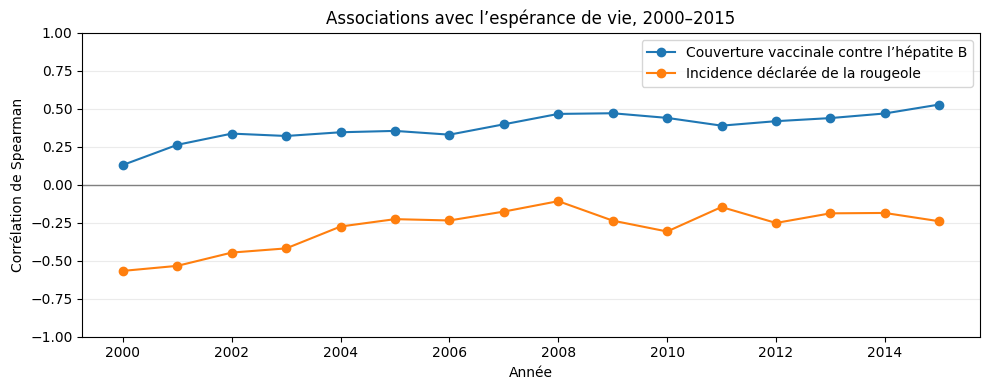

In [28]:
import matplotlib.pyplot as plt

# Sélectionner et renommer les deux séries à visualiser.
correlations_a_tracer = correlations_spearman[
    ["hepatitis_b", "measles_reported_incidence_per_million"]
].rename(columns={
    "hepatitis_b": "Couverture vaccinale contre l’hépatite B",
    "measles_reported_incidence_per_million": "Incidence déclarée de la rougeole",
})

# Tracer les coefficients annuels sur l'échelle complète de Spearman.
ax = correlations_a_tracer.plot(
    marker="o",
    figsize=(10, 4),
    ylim=(-1, 1),
    xlabel="Année",
    ylabel="Corrélation de Spearman",
    title="Associations avec l’espérance de vie, 2000–2015",
)
ax.axhline(0, color="gray", linewidth=1)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

Le graphique confirme que le signe reste stable, mais que la force des associations varie. Pour l’hépatite B, la corrélation passe de +0,131 en 2000 à +0,528 en 2015, alors que le nombre de pays inclus passe de 84 à 174.

### 4.3 Vérifier l’écart sur les mêmes pays
On va recalculer les deux coefficients en gardant uniquement les pays où la couverture vaccinale contre l’hépatite B et l’espérance de vie sont renseignées aux deux dates. Ajoute cette cellule après le graphique.

In [29]:
# Garder les paires disponibles en 2000 et en 2015.
annees_comparaison = [2000, 2015]
hepatite_b = df_cible_disponible.loc[
    df_cible_disponible["year"].isin(annees_comparaison),
    ["iso3", "year", "hepatitis_b", variable_cible],
].dropna(subset=["hepatitis_b"])

# Identifier les pays qui ont une paire disponible aux deux dates.
nb_dates_par_pays = hepatite_b.groupby("iso3")["year"].nunique()
pays_communs_hepatite_b = nb_dates_par_pays[nb_dates_par_pays.eq(2)].index

hepatite_b_pays_communs = hepatite_b.loc[
    hepatite_b["iso3"].isin(pays_communs_hepatite_b)
]

# Recalculer les corrélations sur ce même groupe de pays.
spearman_pays_communs = (
    hepatite_b_pays_communs.groupby("year")[["hepatitis_b", variable_cible]]
    .apply(lambda groupe: groupe["hepatitis_b"].corr(
        groupe[variable_cible], method="spearman"
    ))
)

# Comparer les deux résultats année par année.
comparaison_hepatite_b = pd.DataFrame({
    "paires_disponibles": paires_disponibles_par_annee.loc[
        annees_comparaison, "hepatitis_b"
    ],
    "spearman_paires_disponibles": correlations_spearman.loc[
        annees_comparaison, "hepatitis_b"
    ],
    "pays_communs": len(pays_communs_hepatite_b),
    "spearman_pays_communs": spearman_pays_communs,
})

display(comparaison_hepatite_b.round(3))

,paires_disponibles,spearman_paires_disponibles,pays_communs,spearman_pays_communs
year,,,,
2000,84,0.131,84,0.131
2015,174,0.528,84,0.388


#### Hépatite B : comparaison sur les mêmes pays

Avec toutes les paires disponibles, la corrélation de Spearman entre la
couverture vaccinale contre l’hépatite B et l’espérance de vie passe de
**+0,131 en 2000** (84 pays) à **+0,528 en 2015** (174 pays).

En limitant la comparaison aux **84 pays renseignés aux deux dates**, le
coefficient de 2015 est de **+0,388**. L’écart entre les deux années passe
ainsi de **+0,397 à +0,257**. La composition du groupe influe donc sur
l’ampleur de l’écart observé. L’association reste plus forte en 2015
au sein du même groupe de pays.

Cette comparaison décrit une évolution de l’association entre pays.
Elle ne permet pas d’attribuer cette évolution à la vaccination.

### 4.4 Synthétiser les associations des neuf indicateurs

Avant de conclure LEP-17, faisons un tableau avec une ligne par indicateur. On classera les indicateurs selon la valeur absolue de leur corrélation médiane, tout en gardant le signe, la plage des coefficients et le nombre de pays utilisés. Ce tableau servira aussi pour la synthèse LEP-19.

In [30]:
# Résumer les 16 coefficients annuels pour chaque indicateur.
synthese_lep17 = (
    correlations_spearman.agg(["median", "min", "max"]).T
    .rename(columns={
        "median": "spearman_median",
        "min": "spearman_min",
        "max": "spearman_max",
    })
)

# Ajouter le plus petit et le plus grand effectif annuel.
synthese_lep17["pays_min"] = paires_disponibles_par_annee.min()
synthese_lep17["pays_max"] = paires_disponibles_par_annee.max()

# Classer les associations de la plus forte à la plus faible.
synthese_lep17 = synthese_lep17.sort_values(
    "spearman_median", key=lambda valeurs: valeurs.abs(), ascending=False
)

display(synthese_lep17.round(3))

,spearman_median,spearman_min,spearman_max,pays_min,pays_max
under_five_mortality_per_1000_live_births,-0.946,-0.954,-0.940,183,191
infant_mortality_per_1000_live_births,-0.941,-0.945,-0.935,183,191
hiv_aids,-0.776,-0.792,-0.731,183,191
adult_mortality,-0.703,-0.771,-0.548,183,183
overweight_adults_pct_oms,0.629,0.524,0.677,183,189
diphtheria,0.562,0.540,0.666,180,191
polio,0.541,0.508,0.604,180,191
hepatitis_b,0.394,0.131,0.528,84,180
measles_reported_incidence_per_million,-0.238,-0.567,-0.108,160,180


#### Lecture du classement des associations

La mortalité avant cinq ans (ρ médian = −0,946) et la mortalité infantile
(−0,941) arrivent en tête du classement. Leurs coefficients varient peu
d’une année à l’autre. L’indicateur du VIH/SIDA (−0,776) et la mortalité
adulte (−0,703) suivent.

La proportion d’adultes en surpoids présente l’association positive
la plus forte (+0,629), devant les couvertures vaccinales contre
la diphtérie (+0,562) et la polio (+0,541). Ce résultat décrit une
association entre pays et ne renseigne pas sur l’effet du surpoids
sur la longévité individuelle.

L’incidence déclarée de la rougeole se classe dernière selon la valeur
absolue du coefficient médian (−0,238), mais ses coefficients annuels
s’étendent de −0,567 à −0,108. La médiane résume donc le niveau habituel de
l’association, tandis que le minimum et le maximum montrent à quel point
elle varie selon l’année.

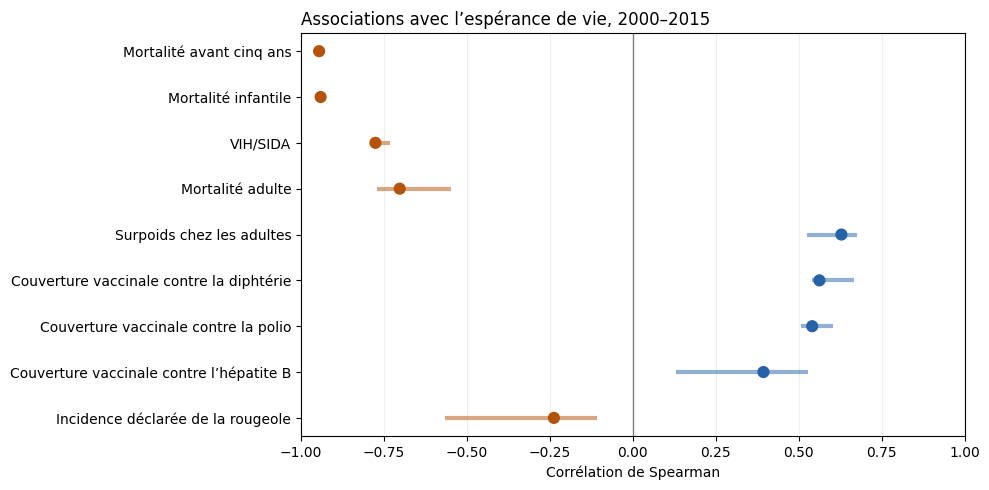

In [32]:
import matplotlib.pyplot as plt

# Donner des noms courts aux indicateurs pour le graphique.
libelles = {
    "under_five_mortality_per_1000_live_births": "Mortalité avant cinq ans",
    "infant_mortality_per_1000_live_births": "Mortalité infantile",
    "hiv_aids": "VIH/SIDA",
    "adult_mortality": "Mortalité adulte",
    "overweight_adults_pct_oms": "Surpoids chez les adultes",
    "diphtheria": "Couverture vaccinale contre la diphtérie",
    "polio": "Couverture vaccinale contre la polio",
    "hepatitis_b": "Couverture vaccinale contre l’hépatite B",
    "measles_reported_incidence_per_million": "Incidence déclarée de la rougeole",
}

# Reprendre l'ordre du tableau de synthèse.
graphique = synthese_lep17.rename(index=libelles)
positions = range(len(graphique))
medianes = graphique["spearman_median"]
couleurs = medianes.map(lambda rho: "#B45309" if rho < 0 else "#2563A6")

fig, ax = plt.subplots(figsize=(10, 5))

# Tracer la plage des coefficients annuels et leur médiane.
ax.hlines(
    y=positions,
    xmin=graphique["spearman_min"],
    xmax=graphique["spearman_max"],
    colors=couleurs,
    linewidth=3,
    alpha=0.5,
)
ax.scatter(medianes, positions, c=couleurs, s=60, zorder=3)

ax.set_yticks(list(positions))
ax.set_yticklabels(graphique.index)
ax.invert_yaxis()
ax.axvline(0, color="gray", linewidth=1)
ax.set_xlim(-1, 1)
ax.set_xlabel("Corrélation de Spearman")
ax.set_title("Associations avec l’espérance de vie, 2000–2015", loc="left")
ax.grid(axis="x", alpha=0.2)

fig.tight_layout()
plt.show()

*Chaque point représente la médiane des 16 corrélations annuelles de Spearman.
Le trait horizontal relie le minimum et le maximum observés de 2000 à 2015.
La ligne verticale à zéro sépare les associations négatives et positives.*

### 6. Exportation des corrélations annuelles et des effectifs

Les résultats de **LEP-17** sont exportés dans un fichier CSV à raison
d’une ligne par année et par indicateur sanitaire. Chaque ligne contient
le coefficient de corrélation de Spearman et le nombre de pays inclus
dans le calcul. Ce fichier permettra de comparer, dans **LEP-19**,
les associations sanitaires de **LEP-17** aux associations
socioéconomiques et éducatives de **LEP-18**, année par année.



In [33]:
from pathlib import Path

# Mettre les corrélations au format long : une ligne par année et indicateur.
coefficients = correlations_spearman.reset_index().melt(
    id_vars="year",
    var_name="indicateur",
    value_name="spearman",
)

# Mettre les effectifs au même format.
effectifs = paires_disponibles_par_annee.reset_index().melt(
    id_vars="year",
    var_name="indicateur",
    value_name="nb_pays",
)

# Associer chaque coefficient au nombre de pays utilisés pour le calcul.
resultats_lep17 = coefficients.merge(
    effectifs,
    on=["year", "indicateur"],
    how="left",
    validate="one_to_one",
).sort_values(["year", "indicateur"])

# Exporter les résultats sans arrondir les coefficients.
fichier_resultats = Path("../reports/tables/lep17_correlations_annuelles.csv")
fichier_resultats.parent.mkdir(parents=True, exist_ok=True)
resultats_lep17.to_csv(fichier_resultats, index=False, encoding="utf-8-sig")

print(f"{len(resultats_lep17)} lignes exportées vers {fichier_resultats}")

144 lignes exportées vers ..\reports\tables\lep17_correlations_annuelles.csv
